# Tilted Gflow Results Visualizer

This notebook contains my process for altering the GFlowNet code to include a tilted factor (implemented in `GFlowNetBase`) and data visualization. For easier visualization of results, I combined all data from different output folders into a single database. That database can be imported into this notebook for easy plotting.

### 1. Changes to `GFlowNetBase`


The idea is to sample actions such that we can bias or tilt our results toward a lower energy solution. 

The key is to do this when the model samples actions. Our calculation of $\pi$, the probability distribution over the next actions to take, can be multiplied by a tilted matrix containing the quantity 

$$\frac{\textbf{energy after }- \textbf{energy before} }{T}$$


```python
    @torch.no_grad() 
    # Note: No gradient used for initial graph determination, then replay_batch re-runs with gradients. 
    def _sample_actions_batch(self, B, eps):
        """
        Advance trajectories together, one position at a time by sampling.
        Returns the recorded actions [B, D]
        """
        D = self.env.D
        spins = torch.zeros(B, D, device=self.device) # size (B, D)
        mask = torch.zeros(B, D, device=self.device) # size (B, D)
        actions = torch.zeros(B, D, dtype=torch.long, device=self.device)
        for t in range(D):
            logits = self.policy(spins, mask, t)

            
            # ------ Goal: Tilt Probabilities of Actions by an energy "kick" ------ 
            TILTING=True
            if TILTING:
                
                tilt_strength = getattr(self, "tilt_strength", 1.0) # Hyperparameter: 0 disables tilt.
                # Collect the candidate spins and the proposed energy changes
                candidates = spins[:, None, :].expand(-1, 2, -1).clone()
                candidates[:, :, t] = spins.new_tensor([-1.0, 1.0])
                
                energy_after = self.env.energy_batch(candidates.reshape(-1, self.env.D)).reshape(-1, 2)
                energy_before = self.env.energy_batch(spins).unsqueeze(1)

                
                # Tilt the policy unnormalized logits by an energy score
                transition_scores = -(energy_after - energy_before) / self.T
                tilted_logits = logits + tilt_strength * transition_scores
                
                pi = torch.softmax(tilted_logits, dim=-1)
            else: 
                # No tilting, previous implementation for pi, policy directly uses logits
                pi = torch.softmax(logits, dim=-1)
            # ----------------------- 

            q = (1.0 - eps) * pi + eps / pi.shape[-1]
            a = torch.multinomial(q, 1).squeeze(-1)
            actions[:, t] = a
            spins[:, t] = torch.where(a == 0, -1.0, 1.0)
            mask[:, t] = 1.0
        return actions
```

## 2. Record Early Stopping KC results

I needed some helper tools to record the intermediate KC values during training, since the current GFN implementation does not collect intermediate KC values. The python file in GFN_Thesis/tilt_early_probe.py collects data at the specified intermeriate checkpoints, allowing us to look at early convergence of KL values before the final value. Some of the key functions are included here, for the full file see the github.

In [ ]:
"""
Exact early-training probe for the fixed-order TB/KC code.

Every checkpoint records exact KL(q||p), KL(p||q), TV, observable errors, entropy,
parameter displacement, preclip gradient norm, clipping fraction, and active optimizer/elapsed times.
 current training-target KL is also recorded.

Output: outputs/tilt_early_TIMESTAMP/run_*.json plus manifest.json.
importer already scans GFN_Thesis/outputs. These JSON files have per-checkpoint
metrics, not the old format; load curve records for plotting.
Partial runs are explicitly marked time_cap.
"""
import torch
import numpy as np

CHECKPOINTS = (0,1,5,10,25,50,100,200,400,800)

def configurations(args):
    seeds = [0] if args.pilot else list(range(args.seeds))
    temperatures = [2.27] if args.pilot else args.temperatures
    blocks = list(iter_tools.product(seeds, args.schedules, temperatures, ['TB','KC']))
    # Shuffle comparison blocks; keep the two tilt strengths adjacent.
    random.Random(9147).shuffle(blocks)
    runs=[]
    for seed,schedule,T,method in blocks:
        strengths=[0.,1.]
        random.Random(f'{seed}:{schedule}:{T}:{method}').shuffle(strengths)
        for strength in strengths:
            runs.append(dict(seed=seed,schedule=schedule,T=T,method=method,tilt_strength=strength,
                 variant='baseline' if strength==0 else 'tilt',kind='ising',dag='tree',N=3,D=9,
                 steps=min(args.steps,20) if args.pilot else args.steps,
                 schedule_horizon=args.horizon,batch=args.batch,lr=args.lr,clip=1.,threads=args.threads))
    return runs

def transition_score(g,spins,t):
    candidates=spins[:,None,:].expand(-1,2,-1).clone()
    candidates[:,:,t]=spins.new_tensor([-1.,1.])
    after=g.env.energy_batch(candidates.reshape(-1,g.env.D)).reshape(-1,2)
    return -(after-g.env.energy_batch(spins)[:,None])/g.T

def reference(env,T):
    codes=torch.arange(1<<env.D,dtype=torch.long)
    acts=((codes[:,None]>>torch.arange(env.D))&1).long()
    spins=(2*acts-1).to(torch.get_default_dtype())
    E=env.energy_batch(spins).double()
    lp=-E/T;logZ=torch.logsumexp(lp,0);lp=lp-logZ;p=lp.exp()
    m=spins.double().mean(1)
    return dict(acts=acts,E=E,logp=lp,p=p,m=m,logZ=float(logZ))

def exact_observables(q,ref,T,D):
    E,m=ref['E'],ref['m']
    absm=(q*m.abs()).sum()
    m2=(q*m.square()).sum()
    return dict(energy_per_spin=float((q*E).sum()/D),abs_m=float(absm),
       chi=float(D*(m2-absm.square())/T),frac_m_pos=float(q[m>0].sum()),
       U4=float(1-(q*m.pow(4)).sum()/(3*m2.square()+1e-300)))

def evaluate(g,ref,beta,initial_parameters):
    with preserve_rng(),torch.no_grad():
        raw_lp,ent,_=g._replay_batch(ref['acts'])
        raw_lp=raw_lp.double()
        mass=float(raw_lp.exp().sum())
        if not math.isfinite(mass) or abs(mass-1)>2e-4:
            raise FloatingPointError(f'Terminal probabilities do not sum to one: {mass}')
        lq=raw_lp-torch.logsumexp(raw_lp,0);q=lq.exp();p=ref['p'];lp=ref['logp']
        obs=exact_observables(q,ref,g.T,g.env.D)
        target=exact_observables(p,ref,g.T,g.env.D)
        tilted_target=-beta*ref['E']/g.T
        tilted_target-=torch.logsumexp(tilted_target,0)
        obs.update(kl_qp=float((q*(lq-lp)).sum()),kl_pq=float((p*(lp-lq)).sum()),
          tv=float((q-p).abs().sum()/2),training_target_kl_qp=float((q*(lq-tilted_target)).sum()),
          probability_mass_before_normalization=mass,mean_action_entropy=float((q*ent.double()).sum()),
          energy_error_per_spin=obs['energy_per_spin']-target['energy_per_spin'],
          abs_m_error=obs['abs_m']-target['abs_m'],chi_error=obs['chi']-target['chi'],
          mode_imbalance=abs(obs['frac_m_pos']-.5),
          parameter_displacement=float(torch.sqrt(sum((p.detach()-p0).square().sum() for p,p0 in zip(g.policy.parameters(),initial_parameters)))))
        return obs

def run(config,args,directory,deadline):
    
    env=SpinEnv('ising',N=3)
    cls=TBGFlowNet if config['method']=='TB' else KCGFlowNet
    g=cls(env,config['T'],device='cpu')
    g.tilt_strength=config['tilt_strength']
    factor=config['lr']/g.opt.param_groups[0]['lr']
    for group in g.opt.param_groups:group['lr']*=factor
    original_schedule=g.schedule
    if config['schedule']=='fixed':g.schedule=lambda iter_,n_iter:(1.,.05,0.)
    ref=reference(env,config['T']);initial_parameters=[p.detach().clone() for p in g.policy.parameters()]
    hashes=source_hashes(g)
    identity=hashlib.sha256(json.dumps(dict(config=config,source_sha256=hashes),sort_keys=True).encode()).hexdigest()[:12]
    path=directory/f"run_{config['method']}_{config['schedule']}_T{config['T']}_s{config['seed']}_tilt{config['tilt_strength']}_{identity}.json"
    if path.is_file() and json.loads(path.read_text()).get('status')=='completed':
        print('Skipping completed:',path.name,flush=True)
        return True
    started=time.monotonic();train_seconds=0.;eval_seconds=0.;updates=0;norm_sum=0.;clipped=0
    result=dict(config=config,source_sha256=hashes,status='starting',curve=[],updates=0,
       torch_version=str(torch.__version__),numpy_version=str(np.__version__),device='cpu',
       evaluation='exact terminal enumeration, all 512 configurations, no exploration',
       policy_class=type(g.policy).__name__,reference={k:v for k,v in exact_observables(ref['p'],ref,g.T,env.D).items()},
       exact_logZ=ref['logZ'],optimizer='Adam',adam_betas=list(g.opt.param_groups[0]['betas']),
       adam_eps=g.opt.param_groups[0]['eps'],optimizer_lrs=[group['lr'] for group in g.opt.param_groups])
    
    def checkpoint(iter_,loss=None):
        nonlocal eval_seconds
        beta,eps,entcoef=g.schedule(iter_,config['schedule_horizon'])
        t=time.monotonic();obs=evaluate(g,ref,beta,initial_parameters);eval_seconds+=time.monotonic()-t
        point=dict(it=iter_,train_seconds=train_seconds,evaluation_seconds=eval_seconds,elapsed_seconds=time.monotonic()-started,
             beta=beta,epsilon=eps,entropy_coef=entcoef,loss=loss,
             mean_preclip_grad_norm=norm_sum/max(1,updates),clip_fraction=clipped/max(1,updates),**obs)
        result['curve'].append(point);result['final']=point
        save()
    
    checkpoint(0)
    checkpoints=set(CHECKPOINTS)|{config['steps']}
    for iter_ in range(1,config['steps']+1):
        tick=time.monotonic()
        loss=g.loss(iter_,config['schedule_horizon'],config['batch'])
        g.opt.zero_grad();loss.backward()
        norm=float(torch.nn.utils.clip_grad_norm_(g.policy.parameters(),config['clip']))
        g.opt.step();train_seconds+=time.monotonic()-tick
        updates=it;norm_sum+=norm;clipped+=int(norm>config['clip'])
        if iter_ in checkpoints:checkpoint(iter_,float(loss.detach()))
    finally:g.schedule=original_schedule

def main():
    #parser.add_arguments ...
    global torch,np,SpinEnv,TBGFlowNet,KCGFlowNet
    from spin_glass_lib import SpinEnv,TBGFlowNet,KCGFlowNet
    #output directory selection...
    start=time.monotonic();
    deadline=start+args.hours*3600
    done=0
    for config in configs:
        if time.monotonic()>=deadline:break
        if not run(config,args,directory,deadline):break
        done+=1
    print(f'Finished {done}/{len(configs)} runs in {(time.monotonic()-start)/60:.1f} minutes. Results: {directory}',flush=True)


## 3. Aggregating all data into SQLlite database

The results from all runs I have access to (Alexa and Sergio) are aggregated into a SQL database using the file 
`gflow-phys/aggregate_plotting/data_aggregate_to_sql.py`, contents included here. The purpose of combining all results in the database is to easily plot results as well as averages over all results, and compare aggregate data from all runs. 



To add more data to the SQL database from new runs, I run `python gflow-phys/aggregate_plotting/data_aggregate_to_sql.py` and editer_ `COLLECT_FROM_FOLDERS` with the location of new output data runs as needed. 


```python 

root = "/local/path/to/my/gflow-phys-folder"
results_filename="sergio_results" # filename for resulting sql database.

## Collects .json, .npz, and .txt data from all subfolders in this folders list. Assumes they are relative to root.
COLLECT_FROM_FOLDERS = ["small_diamonds/results", "GFN_Thesis/outputs", "GFN_Thesis/results/runs", "GFN_Thesis/plot_inputs/timing_cpu_1500",                        "small_diamonds/code/outputs_kc_kitew", "small_diamonds/code/outputs_clip_lr_20261108_153232"...]
                        


db = sqlite3.connect(root / f"aggregate_plotting/{results_filename}.sqlite")

db.execute("CREATE TABLE IF NOT EXISTS archived_files(path TEXT PRIMARY KEY, extension TEXT, content BLOB)")

for folder in COLLECT_FROM_FOLDERS:
    db.executemany("INSERT OR REPLACE INTO archived_files VALUES(?,?,?)", 
                   [(str(p), p.suffix, p.read_bytes()) for p in (root / folder).rglob("*") 
                    if p.is_file() and p.suffix in {".json", ".npz", ".txt"}])

db.commit()

df = pd.json_normalize([{"source_path": path, **json.loads(blob)} for path, blob in db.execute("SELECT path,content FROM archived_files WHERE extension='.json'") if isinstance(json.loads(blob), dict)])  # Raw pandas view
print(db.execute("SELECT COUNT(*) FROM archived_files WHERE extension='.npz'").fetchone()[0], " npz files stored in the database.")

print("Exctracting .npz files into sql database")


db = sqlite3.connect(f"/Users/alexastewart/research/gflow-phys/aggregate_plotting/{results_filename}.sqlite")
db.execute("CREATE TABLE IF NOT EXISTS npz_catalog(source_path TEXT,array_key TEXT,table_name TEXT,shape TEXT,dtype TEXT,PRIMARY KEY(source_path,array_key))")

for path, blob in db.execute("SELECT path,content FROM archived_files WHERE extension='.npz'"):
    with np.load(io.BytesIO(blob), allow_pickle=False) as data:
        for key in data.files:
            a = data[key]
            n = a.shape[0] if a.ndim else 1
            width = int(np.prod(a.shape[1:])) if a.ndim else 1
            rows = a.reshape(n, width)
            table = "npz_" + hashlib.sha256(key.encode()).hexdigest()[:16] + "_" + str(width)
            columns = [f"value_{i}" for i in range(width)]
            db.execute(f"CREATE TABLE IF NOT EXISTS {table}(source_path TEXT,array_key TEXT,row_index INTEGER,{','.join(c + ' REAL' for c in columns)})")
            db.execute(f"DELETE FROM {table} WHERE source_path=? AND array_key=?", (path,key))
            db.execute("INSERT OR REPLACE INTO npz_catalog VALUES(?,?,?,?,?)", (path,key,table,json.dumps(a.shape),str(a.dtype)))
            
            db.commit()
            
            for start in range(0,n,1000): 
                frame = pd.DataFrame(rows[start:start+1000], columns=columns,
                                     index=pd.RangeIndex(start,min(start+1000,n)))
                frame["source_path"] = path
                frame["array_key"] = key
                frame.to_sql(table,db,if_exists="append",index=True,index_label="row_index")
                print(f"{path} | {key}: {min(start+1000,n)}/{n} rows",flush=True)
            print(f"Saved {key}, shape={a.shape}, table={table}",flush=True)
            del rows, a

```

### How the data is Stored

The SQLite database stores JSON, NPZ, and TXT files as bytes in `archived_files`, indexed by their  `path`. 

NPZ arrays are unpacked into numeric tables:
- `npz_catalog` is a table that tells you which table contains each array, such as `samples_lowT_kc`
- sample tables: have one configuration per row, with spins in `value_0`, `value_1`,
- loss tables store interaction and loss
- `run_labels` links file paths to baseline/tilt labels and tilt strength.

#### DataFrames
In this notebook, pandas DataFrames are plotting views built from the SQL data: 
    - `df["chi"]` gives susceptibility values, 
    - `df["variant"]` gives policy labels (tilt or untilted), and
    - `df[df["variant"] == "tilt"]` selects tilted results. 
    
Your early-training `probe` DataFrame instead contains checkpoint measurements: `probe["it"]` gives interaction numbers, `probe["kl_qp"]` gives KL values, and `probe[probe["T"] == 2.27]` selects that temperature.

One row of the `df` contains the results of one run (T, susceptibility, method, seed, iter_s):

In [30]:
# run this block to see example data from df
row=10
display(df.drop(columns="source_path").iloc[row].to_frame(name="Row "+str(row)+" of pandas df (Example)"))

#### Labeling tilted results 

In [48]:
# This block labels my incoming tilt results, in the tilt_early folder.
folder = ROOT / "GFN_Thesis/outputs/tilt_early_20261111_225855"
with sqlite3.connect(SQL_DATABASE) as conn: 
    docs = conn.execute("SELECT path,content FROM archived_files WHERE path LIKE ?", (str(folder)+"/run_%.json",)).fetchall()
runs = [(p,j) for p,b in docs for j in [json.loads(b)] if j.get("status")=="completed"]

assert runs, "Import the early stopping data first"
with sqlite3.connect(SQL_DATABASE) as conn: 
    conn.execute("CREATE TABLE IF NOT EXISTS run_labels(source_path TEXT PRIMARY KEY, neural_variant TEXT, tilt_strength REAL)"); conn.executemany("INSERT OR REPLACE INTO run_labels VALUES(?,?,?)", [(p,j["config"]["variant"],j["config"]["tilt_strength"]) for p,j in runs])

probe = pd.DataFrame([{"source_path":p, **j["config"], **point} for p,j in runs for point in j["curve"]])
probe_stats = probe.groupby(["schedule","T","method","variant","it"]).kl_qp.agg(["mean","sem"]).reset_index()
print(f"Loaded {len(runs)} runs; {len(probe)} evaluations")
#display(probe_stats.head())

Loaded 240 runs; 2400 evaluations


# Comparison between tilted GFlow Implementation and TC/KC methods


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import json
import io
import sys
from pathlib import Path

ROOT = Path("/Users/alexastewart/research/gflow-phys")
SQL_DATABASE = ROOT / "aggregate_plotting/sergio_results.sqlite"
plt.style.use("ggplot")
with sqlite3.connect(SQL_DATABASE.resolve().as_uri() + "?mode=ro", uri=True) as conn:
    docs = conn.execute("SELECT path,content FROM archived_files WHERE path LIKE '%ising_chi_sweep.json'").fetchall()
    labels = dict(conn.execute("SELECT source_path,neural_variant FROM run_labels"))
rows = [{"source_path": p, "variant": labels.get(p, "tilt" if "/outputs/local_iter_3000_tilted" in p else "baseline"), "interactions": 3000 if "/outputs/local_iter_3000" in p else 1500, "seed": int(Path(p).parent.name.removeprefix("seed_")), "method": m, "T": T, "chi": v} for p,b in docs if "/outputs/ising_5x5_refactored/" in p or "/outputs/local_iter_3000" in p for d in [json.loads(b)] for m in ["tb","kc"] if f"chi_{m}_mean" in d for T,v in zip(d["T_grid"],d[f"chi_{m}_mean"])]
df = pd.DataFrame(rows)
df["relative_path"] = df["source_path"].str.removeprefix("/Users/alexastewart/research/gflow-phys/")
# Minimal checks on pandas df - Not empty and no duplicate data
assert not df.empty, "No matching results"
assert not df.duplicated(["interactions","seed","method","T","variant"]).any(), "Repeated runs within a variant: inspect source_path"

# Aggregate mean and std err of mean over all methods, interactions, for big-picture view
stats = df.groupby(["interactions","method","variant","T"])["chi"].agg(["mean","sem"]).reset_index()

### Training Budget Comparison

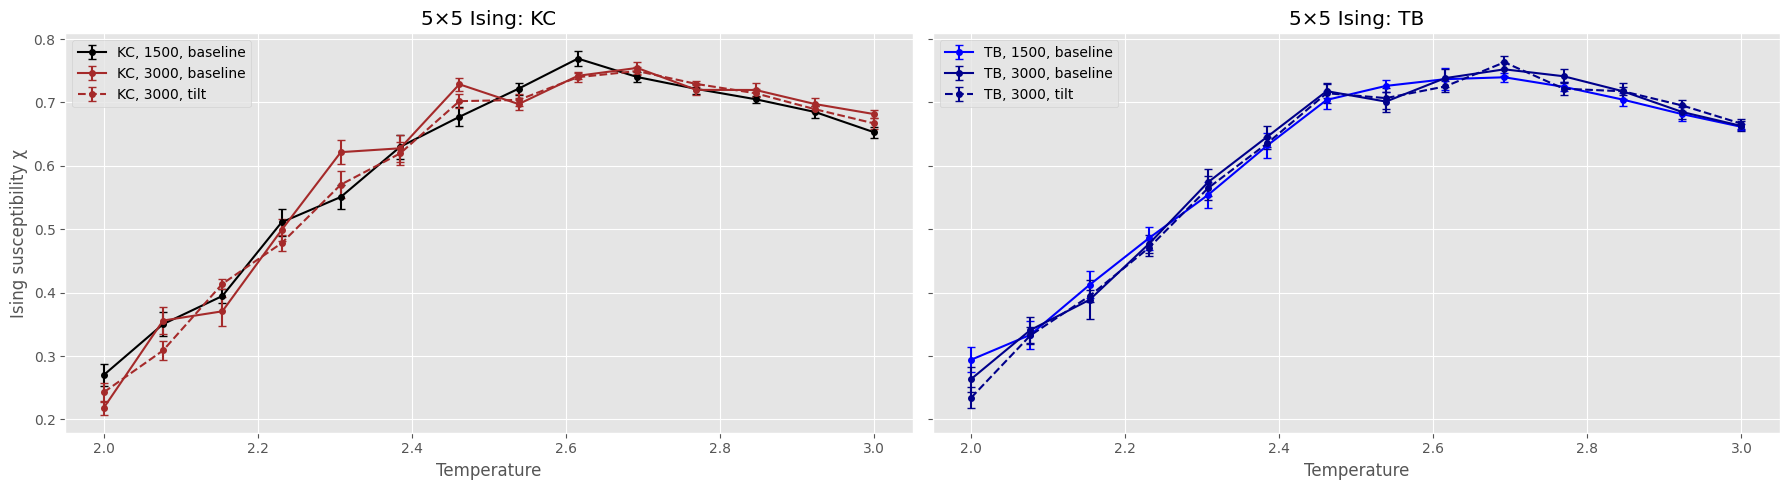

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
colors = {"tb": {3000: "darkblue", 1500: "blue"}, "kc": {3000: "brown", 1500: "black"}}
for ax, name in zip(axes, ["kc", "tb"]):
    for (interactions, method, variant), g in stats.groupby(["interactions", "method", "variant"]):
        if method.lower() == name:
            ax.errorbar(g["T"], g["mean"], yerr=g["sem"].fillna(0), ms=4,color=colors[method][interactions], linestyle="--" if variant == "tilt" else "-", marker="o", capsize=3, label=f"{method.upper()}, {interactions}, {variant}")
    ax.set(xlabel="Temperature", title=f"5×5 Ising: {name.upper()}"); ax.legend()
axes[0].set_ylabel("Ising susceptibility χ"); fig.tight_layout(); plt.show()

### Standard Devitation of Susceptibility across seeds is higher for low Temperature

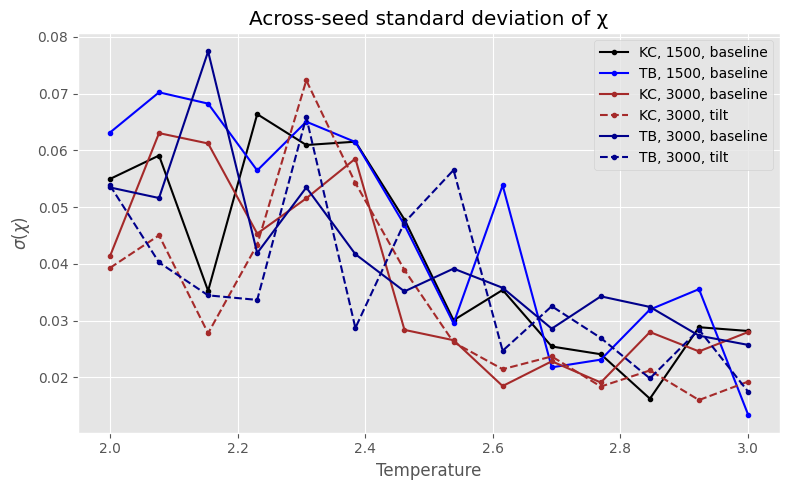

In [87]:
s = df.groupby(["interactions", "method", "variant", "T"]).chi.agg(["std", "count"]).reset_index()
s = s[s["count"] >= 2]
fig, ax = plt.subplots(figsize=(8, 5))
for (iter_s, method, variant), g in s.groupby(["interactions", "method", "variant"]):
    ax.plot(g["T"], g["std"], marker="o", color=colors[method][iter_s], ms=3,linestyle="--" if variant == "tilt" else "-", label=f"{method.upper()}, {iter_s}, {variant}")
ax.set(xlabel="Temperature", ylabel=r"$\sigma{(\chi)}$", title="Across-seed standard deviation of χ")
ax.legend(); plt.tight_layout(); plt.show()

### Early Stopping Exact KL Probe shows different behavior before convergence for Tilted Distribution on 3x3 Ising

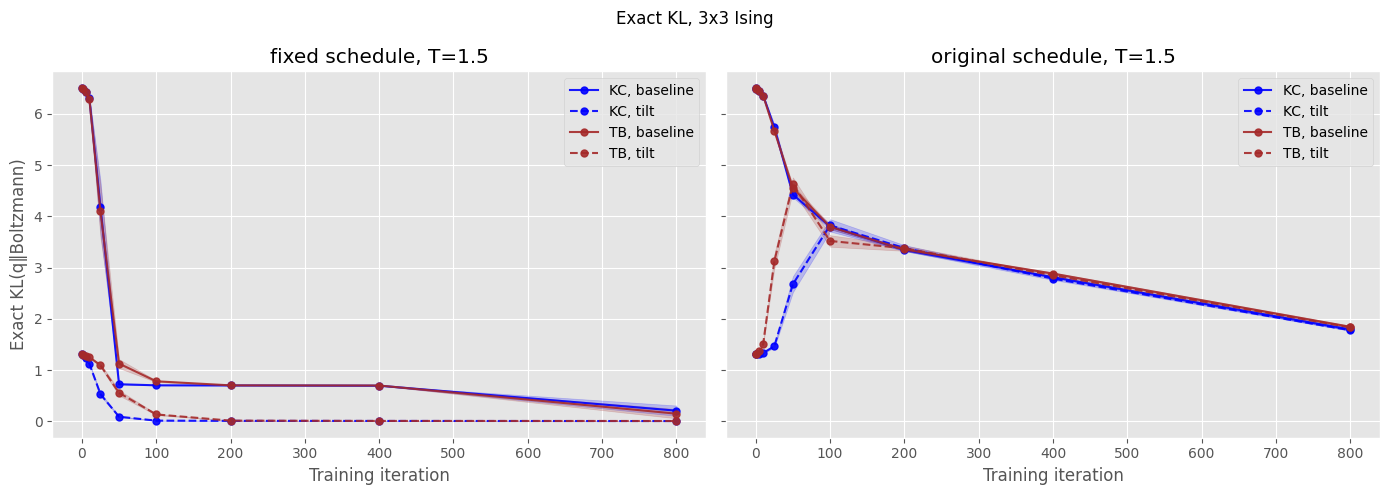

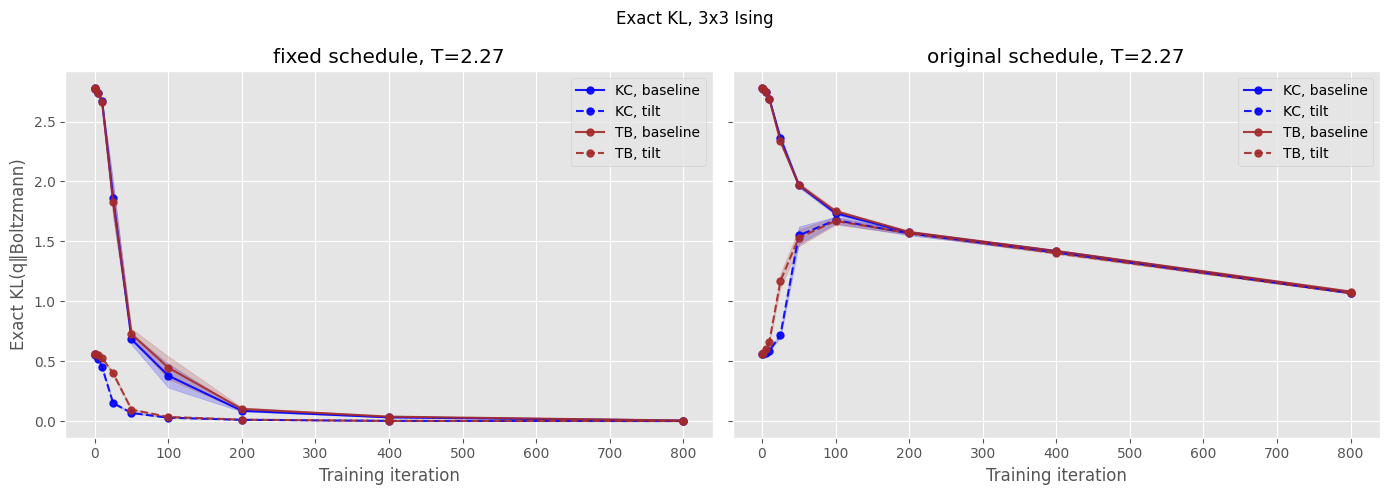

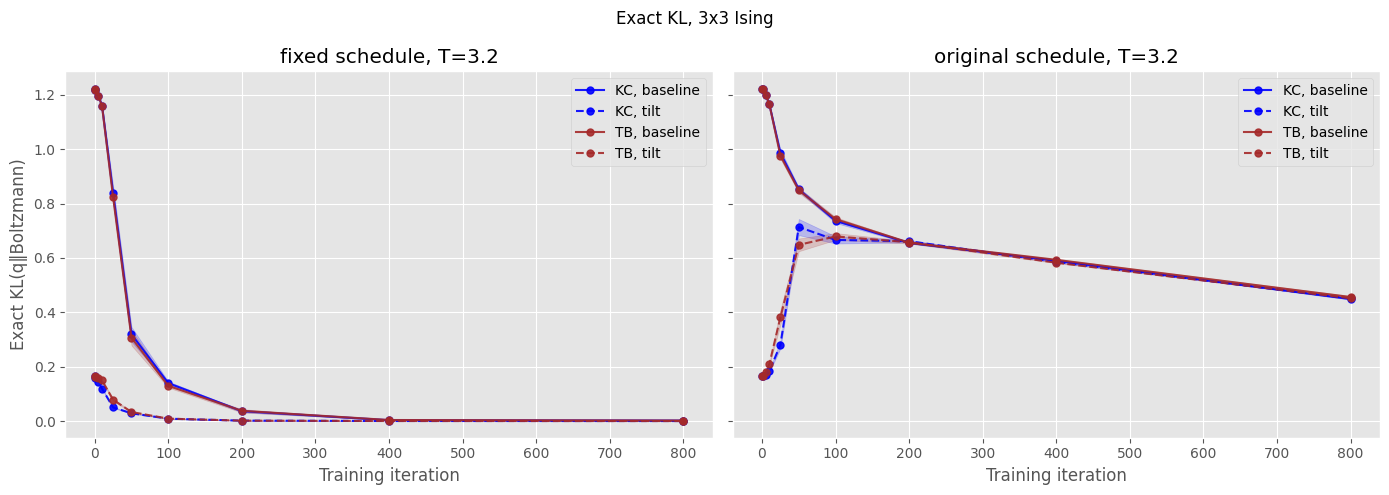

In [107]:
# Plot early stopping results for Tilted vs untilted implementations of 3x3 Ising
colors={"baseline":{"KC":"blue","TB":"brown"},"tilt":{"KC":"blue","TB":"brown"}}

probe = pd.DataFrame([{"source_path":p, **j["config"], **point} for p,j in runs for point in j["curve"]])
probe_stats = probe.groupby(["schedule","T","method","variant","it"]).kl_qp.agg(["mean","sem"]).reset_index()

SAME_Y_SCALE=False
for T in [1.5, 2.27, 3.2]:
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, schedule in zip(axes, ["fixed", "original"]):
        d = probe_stats[(probe_stats["T"] == T) & (probe_stats.schedule == schedule)]
        for (method, variant), g in d.groupby(["method", "variant"]):
            clr=colors[variant][method]
            g = g.sort_values("it")
            line = ax.plot(g["it"], g["mean"], marker="o",alpha=0.9,color=clr,ms=5,linestyle="--" if variant=="tilt" else "-", label=f"{method}, {variant}")[0]
            ax.fill_between(g["it"], (g["mean"]-g["sem"].fillna(0)).clip(lower=0), g["mean"]+g["sem"].fillna(0), color=line.get_color(), alpha=.2)
        ax.set(xlabel="Training iteration", title=f"{schedule} schedule, T={T}")#, yscale="symlog")
        ax.legend()
        if SAME_Y_SCALE:
            ax.set(ylim=(-0.4,10))
    axes[0].set_ylabel("Exact KL(q‖Boltzmann)")
    fig.suptitle("Exact KL, 3x3 Ising")
    fig.tight_layout()
    plt.show()



## Scheduling Details

| Schedule type | Update | Values  | Used in |
|---|---|---|---|
| Fixed training settings | $\beta_i=1,\ \epsilon_i=0.05,\ c_{H,i}=0$ |  In the probes, `--schedules fixed` disables entropy decay | `probe` fixed schedule |
| Linear reward annealing | $\beta_i=0.3+0.7f$ |  set `--entropy_coef0`,`--entropy_anneal_frac`, and `--n_iter` |`tc_sweep`|
| Linear exploration decay | $\epsilon_i=0.8-0.75f$ | Original, horizon \(H=3000\) |`tc_sweep`|
| Linear entropy decay | $c_{H,i}=0.05\max(0,1-i/(0.8H)$ |  `--entropy_anneal_frac` (default 0.8).|`tc_sweep`|
| Constant learning rate | $\eta_i=\eta_0,\quad \eta_{\log Z,i}= 50 \eta_0$ |   $\eta_0=0.001$|`Probes` uses|
| Cosine learning-rate decay | $\eta_i=\eta_{\min}+\frac{\eta_0-\eta_{\min}}{2}[1+\cos(\pi f)]$ | Separate experiments | |
| Linear batch-size ramp | $B_i=\operatorname{round}[B_0+(B_1-B_0)f]$ | 16 to 64, or for `probes`: $B_i=16$ |   |